# Pandas - zadania 11-20

Zakres: wczytywanie danych i selekcja na danych o alkoholu (sekcje 3–4).

Rozwiązuj zadania w pustych komórkach z komentarzem `# tutaj wpisz rozwiązanie`. Gotowe komórki z danymi uruchom bez zmian.

### Import bibliotek i dane

Dane pobieramy z internetu (wymagane połączenie). Funkcja `wczytaj_csv_z_internetu` ma dwie wersje – wybierz wersję dla swojego systemu. Tabela `drinks` zawiera spożycie alkoholu w 193 krajach (porcje piwa, wódki i wina na osobę oraz litry czystego alkoholu).

In [1]:
import numpy as np
import pandas as pd
import requests
from io import StringIO

URL = 'https://raw.githubusercontent.com/justmarkham/pandas-videos/master/data/'

Uruchom **tylko jedną** z dwóch poniższych komórek – zależnie od systemu:

**Wersja dla Windows** – uruchom tę komórkę tylko na Windowsie (bezpośrednie `pd.read_csv(url)`):

In [ ]:
def wczytaj_csv_z_internetu(url, **kwargs):
    return pd.read_csv(url, **kwargs)

**Wersja dla macOS i Linux** – uruchom tę komórkę tylko na macOS lub Linuksie. Pobiera dane biblioteką `requests`, bo `pd.read_csv(url)` potrafi na macOS zgłosić błąd `CERTIFICATE_VERIFY_FAILED`. Ta wersja działa też na Windowsie, więc w razie kłopotów możesz jej użyć wszędzie:

In [2]:
def wczytaj_csv_z_internetu(url, **kwargs):
    odpowiedz = requests.get(url, timeout=30)
    odpowiedz.raise_for_status()
    return pd.read_csv(StringIO(odpowiedz.text), **kwargs)

In [3]:
drinks = wczytaj_csv_z_internetu(URL + 'drinks.csv')
drinks.head()

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa


### Ćwiczenie 11
Tekst `tekst` zawiera dane w formacie CSV: separatorem jest średnik, liczby dziesiętne mają przecinek, a brak danych zapisano jako `brak`.

Wczytaj go do tabeli `produkty` (zamień tekst na „plik” przez `StringIO`) i wyświetl typy kolumn.

__Oczekiwany wynik:__

```
  produkt  cena  ilość
0   chleb   4.5  120.0
1   mleko   3.2    NaN
2     ser  12.9   45.0
```

```
produkt        str
cena       float64
ilość      float64
dtype: object
```

__Wskazówka:__ Użyj `pd.read_csv(StringIO(tekst), sep=..., decimal=..., na_values=[...])`.

In [4]:
tekst = '''produkt;cena;ilość
chleb;4,50;120
mleko;3,20;brak
ser;12,90;45'''
print(tekst)

produkt;cena;ilość
chleb;4,50;120
mleko;3,20;brak
ser;12,90;45


In [8]:
from io import StringIO
df = pd.read_csv(StringIO(tekst), sep=";", na_values=['brak'])
print(df)
print(df.dtypes)

  produkt   cena  ilość
0   chleb   4,50  120.0
1   mleko   3,20    NaN
2     ser  12,90   45.0
produkt        str
cena           str
ilość      float64
dtype: object


In [19]:
df['cena'].str.replace(',', '.').astype('float')

0     4.5
1     3.2
2    12.9
Name: cena, dtype: float64

In [6]:
produkty = pd.read_csv(
    StringIO(tekst),
    sep=";",
    decimal=",",
    na_values=["brak"],
)

display(produkty)
display(produkty.dtypes)

,produkt,cena,ilość
0,chleb,4.5,120.0
1,mleko,3.2,NaN
2,ser,12.9,45.0


produkt        str
cena       float64
ilość      float64
dtype: object

### Ćwiczenie 12
Dla tabeli `drinks` wyświetl:

a) liczbę wierszy i kolumn,

b) nazwy kolumn liczbowych,

c) statystyki opisowe kolumny `beer_servings` (zaokrąglone do 1 miejsca po przecinku).

__Oczekiwany wynik:__

```
(193, 6)
```

```
Index(['beer_servings', 'spirit_servings', 'wine_servings', 'total_litres_of_pure_alcohol'], dtype='str')
```

```
count    193.0
mean     106.2
std      101.1
min        0.0
25%       20.0
50%       76.0
75%      188.0
max      376.0
Name: beer_servings, dtype: float64
```

__Wskazówka:__ Użyj `shape`, `select_dtypes(include='number')` (i atrybutu `columns`) oraz `describe()`.

In [20]:
print(drinks.shape)
print(drinks.select_dtypes(include='number').columns)
print(drinks.describe()['beer_servings'].round(1))

(193, 6)
Index(['beer_servings', 'spirit_servings', 'wine_servings',
       'total_litres_of_pure_alcohol'],
      dtype='str')
count    193.0
mean     106.2
std      101.1
min        0.0
25%       20.0
50%       76.0
75%      188.0
max      376.0
Name: beer_servings, dtype: float64


### Ćwiczenie 13
Podaj procentowy udział trzech najliczniej reprezentowanych kontynentów w tabeli `drinks` (zaokrąglony do 1 miejsca po przecinku).

__Oczekiwany wynik:__

```
continent
Africa    27.5
Europe    23.3
Asia      22.8
Name: proportion, dtype: float64
```

__Wskazówka:__ Użyj `value_counts(normalize=True)`, pomnóż przez 100 i weź pierwsze trzy wartości.

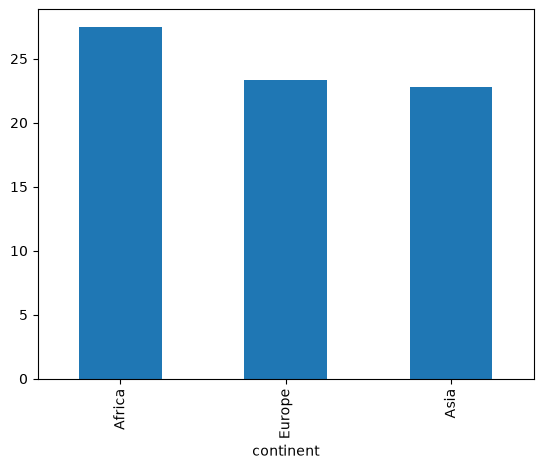

In [27]:
(drinks['continent'].value_counts(normalize=True) * 100).round(1).head(3).plot(kind='bar');

### Ćwiczenie 14
Wyświetl pięć krajów o największym spożyciu wina (kolumny `country` i `wine_servings`).

__Oczekiwany wynik:__

```
         country  wine_servings
61        France            370
136     Portugal            339
3        Andorra            312
166  Switzerland            280
48       Denmark            278
```

__Wskazówka:__ Użyj `sort_values()` z parametrem _ascending=False_, wybierz dwie kolumny i weź pięć pierwszych wierszy.

In [28]:
drinks.sort_values('wine_servings', ascending=False)[['country', 'wine_servings']].head(5)

,country,wine_servings
61,France,370
136,Portugal,339
3,Andorra,312
166,Switzerland,280
48,Denmark,278


### Ćwiczenie 15
Ustaw kolumnę `country` jako indeks (zapisz wynik w zmiennej `napoje`). Następnie wybierz porcje piwa i wina dla Polski, Niemiec i Czech (`'Czech Republic'`).

__Oczekiwany wynik:__

```
                beer_servings  wine_servings
country                                     
Poland                    343             56
Germany                   346            175
Czech Republic            361            134
```

__Wskazówka:__ Użyj `set_index()` oraz `loc` z dwiema listami: etykiet wierszy i nazw kolumn.

In [29]:
drinks

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
188,Venezuela,333,100,3,7.7,South America
189,Vietnam,111,2,1,2.0,Asia
190,Yemen,6,0,0,0.1,Asia
191,Zambia,32,19,4,2.5,Africa


In [30]:
napoje = drinks.set_index('country')
napoje.loc[['Poland', 'Germany', 'Czech Republic'], ['beer_servings', 'wine_servings']]

,beer_servings,wine_servings
country,,
Poland,343,56
Germany,346,175
Czech Republic,361,134


### Ćwiczenie 16
Z tabeli `drinks` wybierz wiersze o pozycjach 10–14 i kolumny `beer_servings`, `spirit_servings`, `wine_servings` (kolumny o pozycjach 1–3). Wykonaj to na dwa sposoby: przez `iloc` oraz przez `loc`.

__Oczekiwany wynik (w obu przypadkach taki sam):__

```
    beer_servings  spirit_servings  wine_servings
10             21               46              5
11            122              176             51
12             42               63              7
13              0                0              0
14            143              173             36
```

__Wskazówka:__ Przy `iloc` prawy koniec wycinka jest wykluczony, przy `loc` – włączony. Etykiety wierszy w tej tabeli to liczby 0, 1, 2…

In [31]:
# Rozwiązanie 1
drinks.iloc[10:15, 1:4]

,beer_servings,spirit_servings,wine_servings
10,21,46,5
11,122,176,51
12,42,63,7
13,0,0,0
14,143,173,36


In [32]:
# Rozwiązanie 2
drinks.loc[10:14, 'beer_servings':'wine_servings']

,beer_servings,spirit_servings,wine_servings
10,21,46,5
11,122,176,51
12,42,63,7
13,0,0,0
14,143,173,36


In [34]:
napoje.loc['Afghanistan':'Algeria', 'beer_servings':'wine_servings']

,beer_servings,spirit_servings,wine_servings
country,,,
Afghanistan,0,0,0
Albania,89,132,54
Algeria,25,0,14


### Ćwiczenie 17
Wybierz kraje europejskie, w których spożycie wina jest większe niż 200 porcji, a spożycie piwa mniejsze niż 150 porcji. Wyświetl kolumny `country`, `beer_servings` i `wine_servings`.

__Oczekiwany wynik:__

```
   country  beer_servings  wine_servings
61  France            127            370
67  Greece            133            218
83   Italy             85            237
```

__Wskazówka:__ Połącz trzy warunki operatorem `&` (pamiętaj o nawiasach).

In [38]:
drinks[(drinks['continent'] == 'Europe') & (drinks['wine_servings'] > 200) & (drinks['beer_servings'] < 150)][['country', 'beer_servings', 'wine_servings']]

,country,beer_servings,wine_servings
61,France,127,370
67,Greece,133,218
83,Italy,85,237


### Ćwiczenie 18
a) Wybierz kraje z Afryki lub Oceanii, w których całkowite spożycie czystego alkoholu (`total_litres_of_pure_alcohol`) mieści się między 8 a 10 litrów włącznie. Wyświetl kolumny `country`, `continent` i `total_litres_of_pure_alcohol`.

b) Policz kraje, których nazwa zawiera fragment `'stan'`.

__Oczekiwany wynik:__

```
          country continent  total_litres_of_pure_alcohol
62          Gabon    Africa                           8.9
121   New Zealand   Oceania                           9.3
124       Nigeria    Africa                           9.1
159  South Africa    Africa                           8.2
179        Uganda    Africa                           8.3
```

```
7
```

__Wskazówka:__ Użyj `isin()`, `between()` oraz `str.contains()`. Liczbę wartości `True` w masce policzysz przez `sum()`.

In [39]:
drinks[drinks['continent'].isin(['Africa', 'Oceania']) & drinks['total_litres_of_pure_alcohol'].between(8, 10)][['country', 'continent', 'total_litres_of_pure_alcohol']]

,country,continent,total_litres_of_pure_alcohol
62,Gabon,Africa,8.9
121,New Zealand,Oceania,9.3
124,Nigeria,Africa,9.1
159,South Africa,Africa,8.2
179,Uganda,Africa,8.3


In [48]:
drinks[drinks['country'].str.contains('a')]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
0,Afghanistan,0,0,0,0.0,Asia
1,Albania,89,132,54,4.9,Europe
2,Algeria,25,0,14,0.7,Africa
3,Andorra,245,138,312,12.4,Europe
4,Angola,217,57,45,5.9,Africa
...,...,...,...,...,...,...
187,Vanuatu,21,18,11,0.9,Oceania
188,Venezuela,333,100,3,7.7,South America
189,Vietnam,111,2,1,2.0,Asia
191,Zambia,32,19,4,2.5,Africa


In [57]:
drinks[(drinks['country'].str.startswith('Z'))|(drinks['country'].str.startswith('P'))]

,country,beer_servings,spirit_servings,wine_servings,total_litres_of_pure_alcohol,continent
128,Pakistan,0,0,0,0.0,Asia
129,Palau,306,63,23,6.9,Oceania
130,Panama,285,104,18,7.2,North America
131,Papua New Guinea,44,39,1,1.5,Oceania
132,Paraguay,213,117,74,7.3,South America
133,Peru,163,160,21,6.1,South America
134,Philippines,71,186,1,4.6,Asia
135,Poland,343,215,56,10.9,Europe
136,Portugal,194,67,339,11.0,Europe
191,Zambia,32,19,4,2.5,Africa


### Ćwiczenie 19
Zmienna `prog` zawiera próg spożycia piwa. Za pomocą metody `query()` wybierz kraje europejskie, w których spożycie piwa jest większe niż `prog`, a spożycie wódki (`spirit_servings`) mniejsze niż 100.

__Oczekiwany wynik:__

```
         country  beer_servings  spirit_servings
9        Austria            279               75
16       Belgium            295               84
120  Netherlands            251               88
156     Slovenia            270               51
```

__Wskazówka:__ W zapytaniu `query()` zmienną Pythona wskazuje się znakiem `@`, np. `'beer_servings > @prog'`.

In [59]:
prog = 250

In [60]:
drinks.query("continent == 'Europe' and beer_servings > @prog and spirit_servings < 100")[['country', 'beer_servings', 'spirit_servings']]

,country,beer_servings,spirit_servings
9,Austria,279,75
16,Belgium,295,84
120,Netherlands,251,88
156,Slovenia,270,51


### Ćwiczenie 20
Zrób kopię tabeli `drinks` (zmienna `kopia`) i dodaj w niej kolumnę `kategoria_piwa`: wartość `'dużo'` dla krajów z co najmniej 250 porcjami piwa, a dla pozostałych `'mało'`. Policz, ile krajów jest w każdej kategorii.

__Oczekiwany wynik:__

```
kategoria_piwa
mało    172
dużo     21
Name: count, dtype: int64
```

__Wskazówka:__ Najpierw przypisz całej kolumnie wartość `'mało'`, potem zmień wybrane wiersze przez `kopia.loc[maska, 'kategoria_piwa'] = ...`. Policz kategorie metodą `value_counts()`.

In [61]:
kopia = drinks.copy()
kopia['kategoria_piwa'] = 'mało'
kopia.loc[kopia['beer_servings'] >= 250, 'kategoria_piwa'] = 'dużo'
kopia['kategoria_piwa'].value_counts()

kategoria_piwa
mało    172
dużo     21
Name: count, dtype: int64